In [ ]:
import pandas as pd 
df=pd.read_csv("European_Bank.csv")
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
print("shape:",df.shape)
print("\ncolumns:",df.columns.tolist()) 
df.info()
df.describe()

shape: (10000, 14)

columns: ['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  floa

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Exited
0    7963
1    2037
Name: count, dtype: int64
churn rate:20.37%


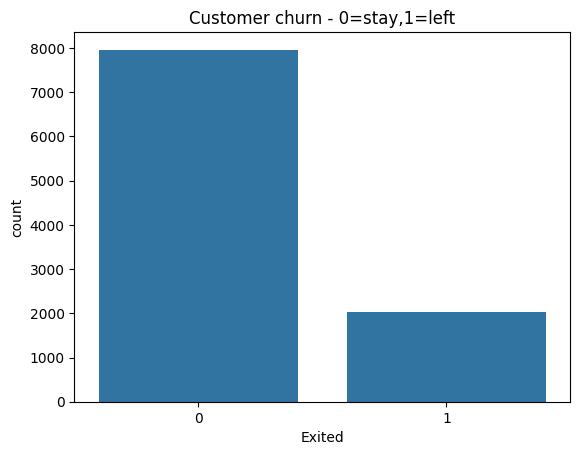

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns   
print(df['Exited'].value_counts()) 
print(f"churn rate:{df['Exited'].mean()*100:.2f}%") 
sns.countplot(x='Exited',data=df) 
plt.title("Customer churn - 0=stay,1=left") 
plt.show()

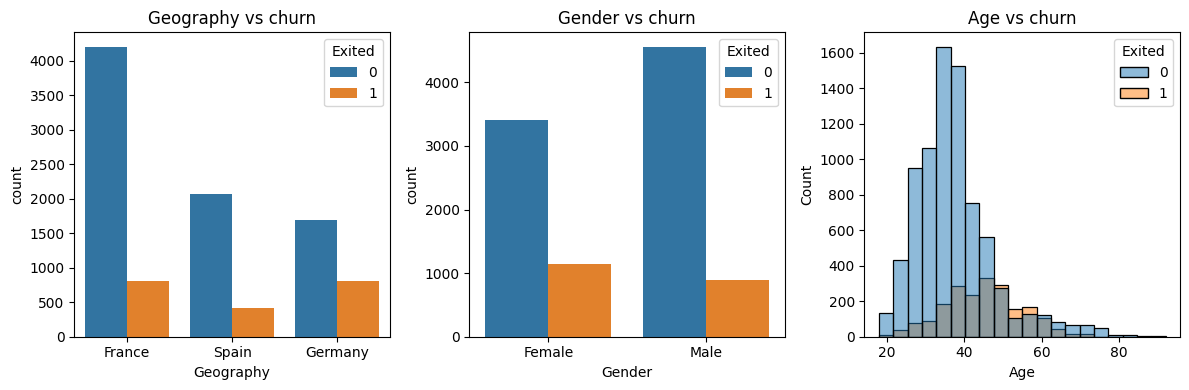


Average Balance of churned customers: 91108.53933726068
Average Balance of retained customers: 72745.2967788522


In [7]:
import pandas as pd
df=pd.read_csv("European_Bank.csv")
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
sns.countplot(x='Geography',hue='Exited',data=df)
plt.title("Geography vs churn")
plt.subplot(1,3,2) 
sns.countplot(x='Gender',hue='Exited',data=df) 
plt.title("Gender vs churn") 
plt.subplot(1,3,3)
sns.histplot(data=df,x='Age',hue='Exited',bins=20)
plt.title("Age vs churn")
plt.tight_layout()
plt.show()
print("\nAverage Balance of churned customers:",df[df['Exited']==1]['Balance'].mean())
print("Average Balance of retained customers:", df[df['Exited']==0]['Balance'].mean())


In [10]:
print("Insight 1:Gender wise churn")
print(df.groupby('Gender')['Exited'].mean())
print("\n Insight 2: Geography wise churn") 
print(df.groupby('Geography')['Exited'].mean())
print("\nInsight 3:Age group")
df['Age group']=pd.cut(df['Age'],bins=[0,30,40,50,60,100],labels=['<30','30-40','40-50','50-60','60+'])
print(df.groupby('Age group')['Exited'].mean())

Insight 1:Gender wise churn
Gender
Female    0.250715
Male      0.164559
Name: Exited, dtype: float64

 Insight 2: Geography wise churn
Geography
France     0.161548
Germany    0.324432
Spain      0.166734
Name: Exited, dtype: float64

Insight 3:Age group
Age group
<30      0.075203
30-40    0.120872
40-50    0.339655
50-60    0.562108
60+      0.247845
Name: Exited, dtype: float64
